### 🟠1.1) download stable-diffusion-2-base

In [3]:
# if needed 
#!pip install --upgrade diffusers transformers accelerate scipy safetensors

In [4]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [3]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

image saved as basic_stable_deffusion_check.png


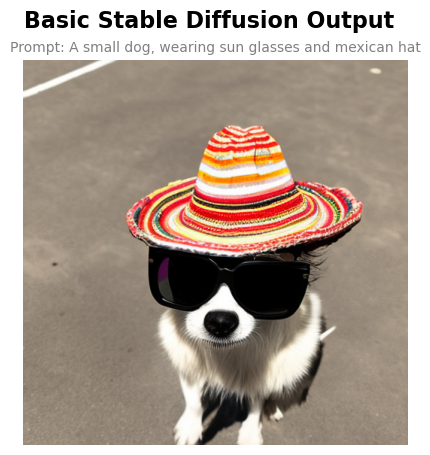

In [4]:
# show image generated
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("basic_stable_deffusion_check.png")

plt.figure(figsize=(5, 5)) 

plt.imshow(img) 
plt.axis("off") 

plt.suptitle("Basic Stable Diffusion Output", fontsize=16, fontweight='bold')
plt.title("Prompt: A small dog, wearing sun glasses and mexican hat", fontsize=10, color='gray')

plt.show() 

In [12]:
import torch
import PIL
import numpy as np
from tqdm.auto import tqdm

def get_text_embeddings(pipe, prompt, negative_prompt, device):
    """
    Encodes the prompt and negative prompt into text embeddings.
    """
    text_input = pipe.tokenizer(
        prompt, 
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    text_embeddings = pipe.text_encoder(text_input.input_ids.to(device))[0]

    uncond_input = pipe.tokenizer(
        negative_prompt,  
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    uncond_embeddings = pipe.text_encoder(uncond_input.input_ids.to(device))[0]

    text_embeddings = torch.cat([uncond_embeddings, text_embeddings])
    return text_embeddings


In [ ]:
def basic_text_to_image_stable(pipe, prompt, negative_prompt="", seed=None, steps=50, guidance_scale=7.5, height=512, width=512):
    """
    Custom bare-bones loop for Text-to-Image generation.
    """
    device = pipe.device
    
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)
    else:
        generator = torch.Generator(device=device)

    # 1. Embed text
    text_embeddings = get_text_embeddings(pipe, prompt, negative_prompt, device)

    # 2. Initialize pure noise in the latent space
    pipe.scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    # Scale the initial noise by the scheduler's required standard deviation
    latents = latents * pipe.scheduler.init_noise_sigma
    
    # 3. Main Denoising Loop
    print("Running Denoising Loop...")
    for i, t in enumerate(tqdm(pipe.scheduler.timesteps)):
        
        # We duplicate the latents (x2) to run two parallel predictions in one batch 
        # (unconditional and conditional) for Classifier-Free Guidance.
        latent_model_input = torch.cat([latents] * 2)
        latent_model_input = pipe.scheduler.scale_model_input(latent_model_input, t)

        # Get the UNet prediction for the noise
        with torch.no_grad():
            noise_pred = pipe.unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

        # Split the prediction back into unconditional and conditional
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)

        # Apply the Guidance formula
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # Subtract the predicted noise from the latents
        latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample
    
    # 4. Final decode from latent space to image space using the VAE
    with torch.no_grad():
        latents = 1 / 0.18215 * latents
        image = pipe.vae.decode(latents).sample

    # 5. Format to PIL Image
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

# 👁️ Dynamic Foveated Diffusion
### *Biologically-Inspired Generative Vision*
> **intro to NeuroAI Final Project** | Roi Maman & Roy Carmel | 2026
 
---

# 🔵1) intro

Biological vision optimizes metabolic bandwidth by restricting peak acuity to the fovea while aggressively compressing peripheral input. Building on this principle, the paper "Foveated Diffusion: Efficient Spatially Adaptive Image and Video Generation" demonstrated that diffusion models can drastically reduce sequence length and latency by processing a designated foveal region at full resolution while downsampling the surrounding periphery.

While the original work relies on rigid, predefined spatial masks, biological visual attention is inherently dynamic. We extend this paradigm by introducing an autonomous, model-intrinsic foveation mechanism: rather than imposing manual masks, our pipeline extracts spatial saliency on the fly from early denoising activations (analogous to V1 cortical receptive fields). This should allows the model to dynamically detect semantically critical focal zones and allocate full-resolution tokens adaptively, achieving biologically grounded compute allocation without manual intervention.

# 🔵2) ?

# 🔵3) implementing the base denoising loop using PixArt-Alpha

### Baseline Implementation: Manual PixArt-Alpha Denoising Loop

Before introducing token-level sequence compression and foveation, we must establish a transparent, uncompressed baseline. Standard high-level interfaces (such as Hugging Face's `DiffusionPipeline`) abstract away token projections and spatial tensor layouts into a "black box," preventing any direct intervention in patch manipulation. 

#### Model Selection: Why PixArt-Alpha?
Selecting the appropriate architectural backbone is critical for evaluating foveated generative rendering under hardware constraints:
* **The Necessity of a Transformer Backbone:** Standard Latent Diffusion Models like Stable Diffusion (v1.5 / SDXL) rely on convolutional U-Net backbones. Convolutions strictly enforce rigid, continuous 2D spatial feature maps ($C \times H \times W$), making dynamic token pruning or asymmetric mixed-resolution representations structurally incompatible without heavy zero-padding or severe architectural degradation. In contrast, **Diffusion Transformers (DiT)** patchify the latent space into discrete, flattened sequences of visual tokens. Because Transformer self-attention naturally processes flexible sequence lengths rather than fixed spatial grids, DiTs allow us to prune, downsample, and recombine spatial patches arbitrarily—translating peripheral compression directly into quadratic $O(N^2)$ self-attention compute and latency savings.
* **PixArt-Alpha vs. Frontier Baselines (FLUX):** The original foveation research benchmarked heavily against frontier architectures like FLUX (\~4B parameters). While powerful, training or adapting 4B-parameter models requires datacenter-scale compute and multi-GPU clusters well beyond what we had access to. PixArt-Alpha (~600M parameters) provides the optimal experimental testbed: it retains the true Transformer token mechanics and high-capacity T5 text conditioning of modern DiTs, yet remains computationally tractable for localized LoRA fine-tuning and sub-second inference on an 8GB VRAM GPU.

#### Objectives of this Baseline
In this section, we construct a fully exposed, manual denoising loop for PixArt-Alpha to achieve two goals:
1. **Validation Baseline:** Establishing ground-truth visual fidelity, execution latency, and token throughput at full sequence length (100% tokens).
2. **Structural Transparency:** Exposing every low-level component—T5 text projection, adaptive layer-norm (adaLN) timestep conditioning, Classifier-Free Guidance (CFG), multi-step ODE scheduling, and tiled VAE decoding—providing the necessary hooks to inject custom foveated sequence manipulation.

### 🟠3.1) first step, tokenizing the prompt, and deleating the model from memory

#### Why Decouple Text Encoding? (VRAM Constraints & Memory Isolation)

PixArt-Alpha relies on the massive **T5-v1.1-XXL** model as its text encoder (~4.3B parameters), requiring nearly 9–10 GB of memory in FP16/BF16. Attempting to keep both the T5 encoder and the 600M-parameter Transformer model in GPU memory simultaneously triggers immediate Out-Of-Memory (OOM) errors on consumer-grade hardware (such as an 8GB VRAM GPU).

To resolve this bottleneck, we decouple the pipeline into a sequential two-stage execution:
* **Pre-computation:** We tokenize the text prompt and pass it through T5 once to extract the semantic embeddings (`prompt_embeds`) and attention masks (`prompt_attention_mask`).
* **Memory Flushing:** Once the embeddings are transferred to RAM, the T5 model and tokenizer are explicitly deleted, followed by manual garbage collection (`gc.collect()`) and CUDA cache clearing (`torch.cuda.empty_cache()`). This frees 100% of the VRAM for the downstream DiT and VAE architectures.

In [1]:
import torch
import PIL
import numpy as np
import gc
from tqdm.auto import tqdm
from diffusers import PixArtAlphaPipeline, Transformer2DModel, AutoencoderKL
from transformers import T5EncoderModel
from IPython.display import display

# --- שלב 1: טעינה זמנית של ה-T5 לצורך קידוד הטקסט בלבד ---
print("Loading T5 Text Encoder temporarily...")
model_id = "PixArt-alpha/PixArt-XL-2-512x512"

# טוענים רק את מקודד השפה ישירות ל-GPU
text_encoder = T5EncoderModel.from_pretrained(
    model_id, 
    subfolder="text_encoder", 
    torch_dtype=torch.float16
).to("cuda")

# טוענים את ה-Tokenizer שלו
from transformers import T5Tokenizer
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")

#prompt = "A small dog, suppressing a smile, wearing sun glasses and mexican hat"
prompt = "a small dog with a mexican hat"
negative_prompt = ""

# תהליך קידוד ידני של הפרומפט בעזרת ה-T5
device = torch.device("cuda")
max_sequence_length = 120 # הערך הסטנדרטי של PixArt

def encode_text(prompt, negative_prompt):
    # קידוד חיובי
    text_inputs = tokenizer(
        prompt,
        padding="max_length",
        max_length=max_sequence_length,
        truncation=True,
        return_tensors="pt",
    )
    text_input_ids = text_inputs.input_ids.to(device)
    prompt_attention_mask = text_inputs.attention_mask.to(device)
    prompt_embeds = text_encoder(text_input_ids, attention_mask=prompt_attention_mask)[0]

    # קידוד שלילי (Classifier-Free Guidance)
    uncond_inputs = tokenizer(
        negative_prompt,
        padding="max_length",
        max_length=max_sequence_length,
        truncation=True,
        return_tensors="pt",
    )
    uncond_input_ids = uncond_inputs.input_ids.to(device)
    negative_attention_mask = uncond_inputs.attention_mask.to(device)
    negative_prompt_embeds = text_encoder(uncond_input_ids, attention_mask=negative_attention_mask)[0]

    return prompt_embeds, prompt_attention_mask, negative_prompt_embeds, negative_attention_mask

print("Encoding prompt...")
with torch.no_grad():
    p_embeds, p_mask, n_embeds, n_mask = encode_text(prompt, negative_prompt)

# שילוב לטובת ה-CFG (שלילי למעלה, חיובי למטה)
prompt_embeds = torch.cat([n_embeds, p_embeds], dim=0)
prompt_attention_mask = torch.cat([n_mask, p_mask], dim=0)

# --- מחיקה מוחלטת של ה-T5 מהזיכרון! ---
print("Unloading T5 from VRAM...")
del text_encoder
del tokenizer
torch.cuda.empty_cache()
gc.collect()
print(f"VRAM after clearing T5: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading T5 Text Encoder temporarily...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Encoding prompt...
Unloading T5 from VRAM...
VRAM after clearing T5: 0.01 GB


### 🟠3.2) loading the model, and running it on the pre-made embeddings

#### Manual Diffusion Inference on Pre-computed Embeddings

With GPU memory cleared, we load the **Transformer2DModel (DiT)** and the **AutoencoderKL (VAE)** to execute the manual denoising loop:

1. **Latent Noise Initialization:** We sample standard Gaussian noise scaled by the scheduler's initial noise standard deviation (`init_noise_sigma`).
2. **Classifier-Free Guidance (CFG):** At each discrete timestep $t$, the latent batch is duplicated (`torch.cat([x] * 2)`) to compute conditional and unconditional predictions in a single forward pass, combining them via:
   $$\epsilon_\theta = \epsilon_{\text{uncond}} + s \cdot (\epsilon_{\text{text}} - \epsilon_{\text{uncond}})$$
3. **Multi-step Scheduling:** We feed the predicted velocity/noise into `DPMSolverMultistepScheduler` to compute the reverse-time ODE trajectory across 20 timesteps.
4. **Full-Resolution VAE Decoding:** The final denoised latent tensor is scaled by the VAE scaling factor and decoded back to RGB pixel space, establishing our ground-truth fidelity and timing benchmark.

Loading Transformer and VAE to GPU...


Some weights of the model checkpoint at PixArt-alpha/PixArt-XL-2-512x512 were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


Running Denoising Loop on GPU...


  0%|          | 0/20 [00:00<?, ?it/s]

Decoding latents to image...


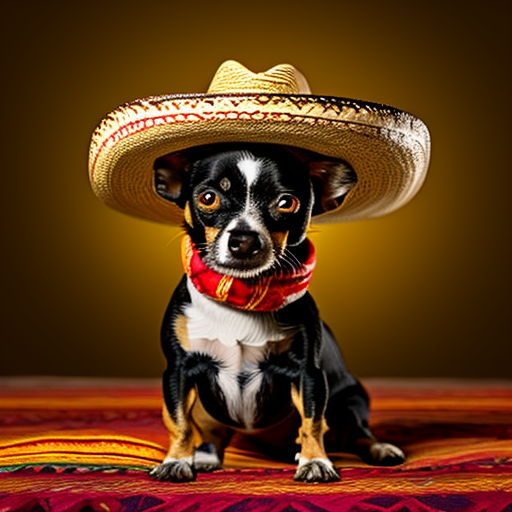

In [2]:
print("Loading Transformer and VAE to GPU...")
transformer = Transformer2DModel.from_pretrained(
    model_id, 
    subfolder="transformer", 
    torch_dtype=torch.float16
).to("cuda")

vae = AutoencoderKL.from_pretrained(
    model_id, 
    subfolder="vae", 
    torch_dtype=torch.float16
).to("cuda")

# טעינת Scheduler סטנדרטי
from diffusers import DPMSolverMultistepScheduler
scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")


# --- שלב 3: לולאת הדיפוזיה הידנית שלנו ---
def run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=4.5, height=512, width=512):
    generator = torch.Generator(device=device).manual_seed(seed)
    
    scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    latents = latents * scheduler.init_noise_sigma

    resolution = torch.tensor([height, width], dtype=torch.float16, device=device).repeat(2, 1)
    aspect_ratio = torch.tensor([float(height / width)], dtype=torch.float16, device=device).repeat(2, 1)
    added_cond_kwargs = {"resolution": resolution, "aspect_ratio": aspect_ratio}

    print("Running Denoising Loop on GPU...")
    for i, t in enumerate(tqdm(scheduler.timesteps)):
        latent_model_input = torch.cat([latents] * 2)
        
        t = t.to(device)
        latent_model_input = scheduler.scale_model_input(latent_model_input, t)

        t_val = t.item() if isinstance(t, torch.Tensor) else t
        t_batch = torch.tensor([t_val, t_val], device=device)

        with torch.no_grad():
            noise_pred = transformer(
                latent_model_input,
                encoder_hidden_states=prompt_embeds,
                encoder_attention_mask=prompt_attention_mask,
                timestep=t_batch,
                added_cond_kwargs=added_cond_kwargs,
                return_dict=False,
            )[0]

        if noise_pred.shape[1] == 8:
            noise_pred, _ = noise_pred.chunk(2, dim=1)

        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        latents = scheduler.step(noise_pred, t, latents).prev_sample
        latents = latents.to(device)

    # פיענוח סופי דרך ה-VAE
    print("Decoding latents to image...")
    with torch.no_grad():
        latents = (1 / vae.config.scaling_factor) * latents
        image = vae.decode(latents.to(vae.dtype)).sample

    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

image = run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=7.5)
display(image)

# 🔵4) Naïve foveated diffusion (training-free mixed-resolution baseline)

The paper's *Naïve Mixed-Resolution Denoising* baseline: the pretrained PixArt denoises a mixed-resolution token sequence, with no training.
- inside the foveation mask: normal high-res tokens (each covers 16x16 pixels)
- outside it: one low-res token per 2x2 block of high-res tokens (covers 32x32 pixels), so 4x fewer tokens in the periphery
- the transformer blocks accept any token sequence; only the patch embedding, the positional embeddings and the unpatchify assume a grid, so we redo those per token. Low-res tokens get PixArt's sin-cos position at the centre of the block they replace (our stand-in for the paper's mixed-resolution RoPE)
- at the end the two parts are decoded separately by the VAE, the periphery is upsampled and the two are blended (Eq. 5-7)

Expected result: scale mismatches / duplicated objects around the fovea boundary (paper Fig. 4-5). Foveated training is what fixes this later.

Uses `transformer`, `vae`, `scheduler`, `prompt_embeds`, `prompt_attention_mask`, `device` and `run_diffusion_loop` from section 3 - run 3.1 and 3.2 first.

### 🟠4.1) foveated tokenization: masks, packing and positions

In [3]:
import time
import torch.nn.functional as F
import matplotlib.pyplot as plt
from diffusers.models.embeddings import get_2d_sincos_pos_embed_from_grid

P = transformer.config.patch_size      # 2 -> one token = 2x2 latent pixels = 16x16 image pixels
C = transformer.config.in_channels     # 4 latent channels
D = transformer.inner_dim              # 1152 hidden size
pe = transformer.pos_embed
POS_SCALE = pe.base_size / pe.height / pe.interpolation_scale   # PixArt's position scaling (=1 for the 512 model)
GRID = pe.height                       # the high-res token grid is GRID x GRID (32x32 for 512x512 images)

def patchify(z):
    """(B, C, H, W) latent grid -> (B, H/P * W/P, P*P*C) tokens, row-major, same layout PixArt uses to unpatchify."""
    B, c, H, W = z.shape
    return z.reshape(B, c, H // P, P, W // P, P).permute(0, 2, 4, 3, 5, 1).reshape(B, (H // P) * (W // P), P * P * c)

def unpatchify(tokens, h, w, c=C):
    """(B, h*w, P*P*c) tokens -> (B, c, h*P, w*P) latent grid."""
    B = tokens.shape[0]
    return tokens.reshape(B, h, w, P, P, c).permute(0, 5, 1, 3, 2, 4).reshape(B, c, h * P, w * P)

def make_circular_mask(center=(0.5, 0.5), radius=0.25, grid=GRID):
    """Circular foveation mask on the high-res token grid. center=(y, x) and radius are fractions of the image size."""
    ys, xs = torch.meshgrid(torch.arange(grid), torch.arange(grid), indexing="ij")
    ys, xs = (ys + 0.5) / grid, (xs + 0.5) / grid
    return (ys - center[0]) ** 2 + (xs - center[1]) ** 2 < radius ** 2

def build_layout(M):
    """
    Foveated token layout from a boolean mask M on the high-res token grid (h x w).
    Inside the fovea we keep every high-res token; outside it, one low-res token replaces each 2x2 block.
    Sequence order: [high-res tokens (row-major) | low-res tokens (row-major)].
    """
    h, w = M.shape
    Mb = M.reshape(h // 2, 2, w // 2, 2).any(dim=3).any(dim=1)     # block grid: True = block is in the fovea
    M = Mb.repeat_interleave(2, 0).repeat_interleave(2, 1)          # snap the mask to whole 2x2 blocks
    hi_idx = M.flatten().nonzero().squeeze(1)
    lo_idx = (~Mb).flatten().nonzero().squeeze(1)

    # token coordinates on the high-res token grid, in (x, y) order like PatchEmbed
    ys, xs = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
    hi_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[hi_idx].float()
    ys, xs = torch.meshgrid(torch.arange(h // 2), torch.arange(w // 2), indexing="ij")
    lo_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[lo_idx].float() * 2 + 0.5   # centre of the 2x2 block it replaces
    xy = torch.cat([hi_xy, lo_xy]) * POS_SCALE

    # the same sin-cos embedding PixArt uses, just evaluated at our (possibly fractional) positions
    pos = get_2d_sincos_pos_embed_from_grid(D, xy.T.to(device), output_type="pt").float()[None]

    n_hi, n_lo = len(hi_idx), len(lo_idx)
    return dict(M=M, Mb=Mb, hi_idx=hi_idx.to(device), lo_idx=lo_idx.to(device), pos=pos,
                n_hi=n_hi, n_lo=n_lo, h=h, w=w, token_ratio=(n_hi + n_lo) / (h * w))

### 🟠4.2) PixArt forward pass on a foveated token sequence + sanity checks

In [4]:
@torch.no_grad()
def fov_transformer(x, t, layout, prompt_embeds, prompt_attention_mask):
    """
    PixArt forward pass on a packed foveated token sequence.
    x: (B, L, P*P*C) noisy latent patches -> returns the predicted noise, same shape.
    Same as transformer.forward(), except the steps that assume a regular grid
    (patch embedding, positions, unpatchify) are done per token.
    """
    B = x.shape[0]

    # 1. patch embedding: PixArt's conv (kernel = stride = P) is just a linear layer applied to each patch
    W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C)   # (p, q, c) order, matches patchify()
    h = (F.linear(x, W_in, pe.proj.bias) + layout["pos"]).to(x.dtype)

    # 2. timestep + text conditioning, as in transformer.forward
    #    (resolution/aspect_ratio are ignored by the 512 model; the 1024 model needs real values here)
    t_emb, t_raw = transformer.adaln_single(t.expand(B), {"resolution": None, "aspect_ratio": None},
                                            batch_size=B, hidden_dtype=h.dtype)
    enc = transformer.caption_projection(prompt_embeds).view(B, -1, D)
    enc_bias = ((1 - prompt_attention_mask.to(h.dtype)) * -10000.0).unsqueeze(1)

    # 3. transformer blocks - these don't care about the grid, any token sequence works
    for block in transformer.transformer_blocks:
        h = block(h, attention_mask=None, encoder_hidden_states=enc, encoder_attention_mask=enc_bias,
                  timestep=t_emb, cross_attention_kwargs=None, class_labels=None)

    # 4. output head, per token
    shift, scale = (transformer.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    h = transformer.norm_out(h) * (1 + scale) + shift
    out = transformer.proj_out(h)                                          # (B, L, P*P*8)
    out = out.reshape(B, -1, P * P, transformer.out_channels)[..., :C]    # keep eps, drop the learned-variance channels
    return out.reshape(B, -1, P * P * C)

In [5]:
# sanity checks: with an all-high-res mask the foveated path must reproduce normal PixArt

# 1) positions: our embedding must equal PixArt's own table
full_layout = build_layout(torch.ones(GRID, GRID, dtype=torch.bool))
print("pos-embed max diff :", (full_layout["pos"] - pe.pos_embed).abs().max().item())    # expect ~0

# 2) forward pass: fov_transformer must match transformer(...)
scheduler.set_timesteps(20)
t = scheduler.timesteps[5].to(device)
z = torch.randn(2, C, GRID * P, GRID * P, device=device, dtype=torch.float16)
with torch.no_grad():
    ref = transformer(z, encoder_hidden_states=prompt_embeds, encoder_attention_mask=prompt_attention_mask,
                      timestep=t.expand(2), added_cond_kwargs={"resolution": None, "aspect_ratio": None},
                      return_dict=False)[0][:, :C]
out = unpatchify(fov_transformer(patchify(z), t, full_layout, prompt_embeds, prompt_attention_mask), GRID, GRID)
print("forward max diff   :", (ref - out).abs().max().item(), "| mean |eps|:", ref.abs().mean().item())  # expect small (fp16 noise, ~1e-2 or less)

pos-embed max diff : 0.0
forward max diff   : 0.00390625 | mean |eps|: 0.796875


### 🟠4.3) foveated denoising loop and decoding
Same loop as 3.2, but the latent is a packed sequence of L patches instead of a 64x64 grid.

In [9]:
def to_pil(img):
    img = (img.float() / 2 + 0.5).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()
    return PIL.Image.fromarray((img * 255).round().astype("uint8"))

def foveated_noise(layout, seed):
    """
    Initial noise for the packed sequence, taken from the SAME full-res noise run_diffusion_loop draws for this seed,
    so full-res and foveated runs are directly comparable. Low-res noise = 2x2 average * 2 (keeps unit variance).
    """
    g = torch.Generator(device=device).manual_seed(seed)
    z = torch.randn((1, C, layout["h"] * P, layout["w"] * P), generator=g, device=device, dtype=torch.float16)
    z_lo = (F.avg_pool2d(z.float(), 2) * 2).half()
    return torch.cat([patchify(z)[:, layout["hi_idx"]], patchify(z_lo)[:, layout["lo_idx"]]], dim=1)

def run_foveated_loop(layout, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=4.5):
    scheduler.set_timesteps(steps)
    x = foveated_noise(layout, seed) * scheduler.init_noise_sigma      # (1, L, P*P*C) instead of (1, 4, 64, 64)
    for t in tqdm(scheduler.timesteps):
        t = t.to(device)
        x_in = scheduler.scale_model_input(torch.cat([x] * 2), t)
        eps_uncond, eps_text = fov_transformer(x_in, t, layout, prompt_embeds, prompt_attention_mask).chunk(2)
        eps = eps_uncond + guidance_scale * (eps_text - eps_uncond)
        x = scheduler.step(eps, t, x).prev_sample                     # scheduler math is elementwise, the shape doesn't matter
    return x

@torch.no_grad()
def decode_foveated(x, layout):
    """Split -> decode each part with the VAE -> upsample the periphery -> blend with the mask (paper Eq. 5-7)."""
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    hi = torch.zeros(1, h * w, P * P * C, device=device, dtype=x.dtype)
    lo = torch.zeros(1, (h // 2) * (w // 2), P * P * C, device=device, dtype=x.dtype)
    hi[:, layout["hi_idx"]] = x[:, :n_hi]
    lo[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi, z_lo = unpatchify(hi, h, w), unpatchify(lo, h // 2, w // 2)          # (1,4,64,64) and (1,4,32,32)

    # fill each grid's empty part from the other one, so the VAE decoder doesn't see zeros next to the boundary
    m_hi = layout["M"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    m_lo = layout["Mb"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    z_lo = torch.where(m_lo, F.avg_pool2d(z_hi.float(), 2).to(z_hi.dtype), z_lo)
    z_hi = torch.where(m_hi, z_hi, F.interpolate(z_lo.float(), scale_factor=2, mode="nearest").to(z_hi.dtype))

    img_hi = vae.decode(z_hi / vae.config.scaling_factor).sample                  # (1,3,512,512)
    img_lo = vae.decode(z_lo / vae.config.scaling_factor).sample                  # (1,3,256,256)
    img_lo_up = F.interpolate(img_lo.float(), scale_factor=2, mode="bicubic")
    m_px = layout["M"].float().repeat_interleave(P * 8, 0).repeat_interleave(P * 8, 1).to(device)
    img = m_px * img_hi.float() + (1 - m_px) * img_lo_up
    return to_pil(img), to_pil(img_hi), to_pil(img_lo)

def draw_fovea_border(pil_img, layout, color=(255, 255, 255)):
    """White outline around the high-res region, like the figures in the paper."""
    m = F.interpolate(layout["M"].float()[None, None], size=pil_img.size[::-1], mode="nearest")
    ring = (F.max_pool2d(m, 5, stride=1, padding=2) - m)[0, 0] > 0
    arr = np.array(pil_img)
    arr[ring.numpy()] = color
    return PIL.Image.fromarray(arr)

### 🟠4.4) full high-res vs naive foveated (same prompt, same seed)
At 512x512 there are only 1024 tokens, so attention is not the bottleneck and the speedup is small; the point here is the image quality comparison.

tokens: 240 high-res + 196 low-res = 436 / 1024  (token ratio 43%)
Running Denoising Loop on GPU...


  0%|          | 0/20 [00:00<?, ?it/s]

Decoding latents to image...


  0%|          | 0/20 [00:00<?, ?it/s]

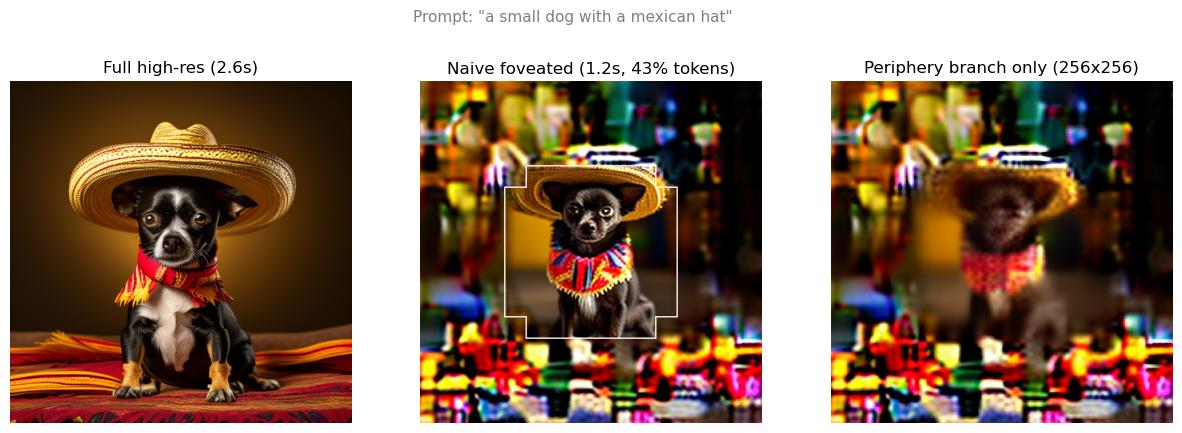

In [15]:
SEED, STEPS, GUIDANCE = 42, 20, 4.5

layout = build_layout(make_circular_mask(center=(0.5, 0.5), radius=0.25))
print(f"tokens: {layout['n_hi']} high-res + {layout['n_lo']} low-res = {layout['n_hi'] + layout['n_lo']} "
      f"/ {layout['h'] * layout['w']}  (token ratio {layout['token_ratio']:.0%})")

torch.cuda.synchronize(); t0 = time.time()
img_full = run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask,
                              seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
torch.cuda.synchronize(); t_full = time.time() - t0

t0 = time.time()
x = run_foveated_loop(layout, prompt_embeds, prompt_attention_mask, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
img_fov, img_hi, img_lo = decode_foveated(x, layout)
torch.cuda.synchronize(); t_fov = time.time() - t0

panels = [
    (img_full, f"Full high-res ({t_full:.1f}s)"),
    (draw_fovea_border(img_fov, layout), f"Naive foveated ({t_fov:.1f}s, {layout['token_ratio']:.0%} tokens)"),
    (img_lo, "Periphery branch only (256x256)"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (im, title) in zip(axes, panels):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle(f'Prompt: "{prompt}"', fontsize=11, color="gray")
plt.show()

### 🟠4.5) different foveation patterns (same prompt and seed, like Fig. 9 in the paper)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

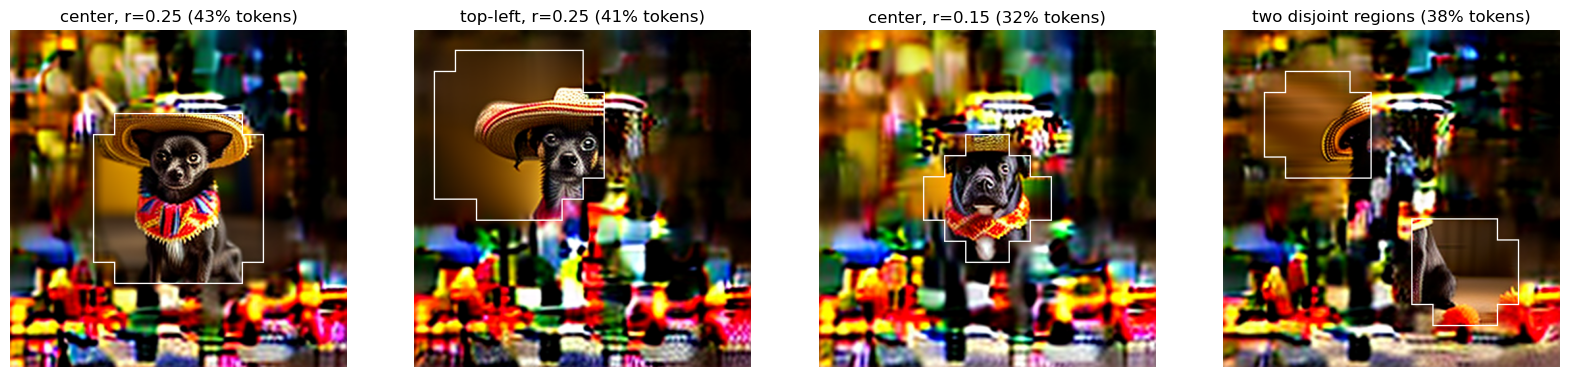

In [16]:
masks = {
    "center, r=0.25":       make_circular_mask((0.5, 0.5), 0.25),
    "top-left, r=0.25":     make_circular_mask((0.3, 0.3), 0.25),
    "center, r=0.15":       make_circular_mask((0.5, 0.5), 0.15),
    "two disjoint regions": make_circular_mask((0.3, 0.3), 0.15) | make_circular_mask((0.7, 0.7), 0.15),
}

fig, axes = plt.subplots(1, len(masks), figsize=(5 * len(masks), 5))
for ax, (name, M) in zip(axes, masks.items()):
    lay = build_layout(M)
    x = run_foveated_loop(lay, prompt_embeds, prompt_attention_mask, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
    img_fov, _, _ = decode_foveated(x, lay)
    ax.imshow(draw_fovea_border(img_fov, lay))
    ax.set_title(f"{name} ({lay['token_ratio']:.0%} tokens)")
    ax.axis("off")
plt.show()

# 🔵5) solving the naive problems - LoRA

### Overcoming Naive Limitations via Parameter-Efficient Adaptation (LoRA)

In the previous section, the zero-shot (training-free) foveated baseline revealed critical failure modes:
1. **Variance & Distribution Shift:** Downsampling the peripheral latent space breaks the isotropic Gaussian noise assumption of diffusion models. The downsampled periphery exhibits severe variance collapse, leading to uncontrolled noise scaling and divergence.
2. **High-Frequency Boundary Discontinuities (Mosaic Artifacts):** Because standard DiT attention expects uniform spatial token resolution, the sharp interface between uncompressed foveal tokens and downsampled peripheral patches creates prominent grid-like boundary seams.
3. **Decoder Saturation & Color Inversion:** As highlighted in the *Foveated Diffusion* literature, out-of-distribution peripheral latents drive the VAE decoder into extreme activation clipping, producing garish, oversaturated neon artifacts.

#### The Solution: Mixed-Resolution LoRA Fine-Tuning
Rather than retraining the entire 600M-parameter DiT backbone from scratch, we inject **Low-Rank Adaptation (LoRA)** into the Multi-Head Attention and MLP projections. By training LoRA on synthetically constructed mixed-resolution token sequences, the model learns to bridge cross-resolution feature distributions and predict dual-scale noise trajectories accurately.

#### Implementation Roadmap
To maintain strict memory safety on an 8GB VRAM constraint, we structure this pipeline into four modular stages:

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_id = "PixArt-alpha/PixArt-XL-2-512x512"

lora_dir = "./pixart_foveated_lora_1hour_final"
cache_file = "diffusiondb_512_cached_data.pt"

FORCE_RECACHE = False #put True here if you want to retrain. 

### 🟠5.1) Offline text and VAE latent caching to eliminate redundant forward passes.

To maximize training throughput and prevent GPU Out-of-Memory (OOM) crashes, we pre-encode the training set:
1. **Text Caching:** 1,000 prompt descriptions from DiffusionDB are tokenized and processed through T5 once. The resulting embeddings and attention masks are moved to system RAM, after which the 10GB T5 model is purged from GPU memory.
2. **Latent Caching ($x_0$):** Target images are resized to the target spatial dimension and encoded via tiled `AutoencoderKL` into clean latent representations ($x_0$), scaled by the model's latent factor, and cached. This eliminates repetitive VAE forward passes during gradient descent.

In [ ]:
#!pip install datasets torchvision
import os
import gc
import torch
import torchvision.transforms as T
from tqdm.auto import tqdm
from datasets import load_dataset
from diffusers import AutoencoderKL
from transformers import T5EncoderModel, T5Tokenizer

if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA found at '{lora_dir}'.")
    print(" No need to cache training data. You can skip directly to inference (Block 4)!")
    cached_text_embeds, cached_text_masks, cached_x0 = [], [], []

elif os.path.exists(cache_file) and not FORCE_RECACHE:
    print(f" Found cached dataset on disk ('{cache_file}'). Loading into RAM...")
    saved_data = torch.load(cache_file, map_location="cpu")
    cached_text_embeds = saved_data["text_embeds"]
    cached_text_masks = saved_data["text_masks"]
    cached_x0 = saved_data["x0"]
    print(f" Loaded {len(cached_x0)} samples in 2 seconds! Ready for training.")

else:
    print("No cache found. Running full data caching pipeline...")
    
    # 1. טעינת 1,000 דוגמאות מתוך DiffusionDB
    print("1. Loading 1,000 samples from DiffusionDB...")
    dataset = load_dataset("poloclub/diffusiondb", "2m_random_1k", split="train")

    # 2. קידוד טקסט באמצעות T5
    print("2. Caching 1,000 Text Embeddings...")
    tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
    text_encoder = T5EncoderModel.from_pretrained(
        model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16
    ).to(device)

    cached_text_embeds = []
    cached_text_masks = []

    with torch.no_grad():
        for item in tqdm(dataset, desc="Encoding prompts"):
            prompt = item["prompt"]
            txt_in = tokenizer(
                prompt, padding="max_length", max_length=120, truncation=True, return_tensors="pt"
            ).to(device)
            emb = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0]
            cached_text_embeds.append(emb.cpu())
            cached_text_masks.append(txt_in.attention_mask.cpu())

    del text_encoder, tokenizer
    torch.cuda.empty_cache()
    gc.collect()

    # 3. קידוד תמונות מהיר ישירות דרך ה-VAE
    print("3. Encoding 1,000 images directly via VAE...")
    vae = AutoencoderKL.from_pretrained(
        model_id, subfolder="vae", torch_dtype=torch.bfloat16
    ).to(device)

    img_transform = T.Compose([
        T.Resize((512, 512)),
        T.ToTensor(),
        T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
    ])

    cached_x0 = []

    with torch.no_grad():
        for item in tqdm(dataset, desc="VAE Encoding"):
            img = item["image"].convert("RGB")
            img_tensor = img_transform(img).unsqueeze(0).to(device=device, dtype=torch.bfloat16)
            
            latent = vae.encode(img_tensor).latent_dist.sample()
            latent = latent * vae.config.scaling_factor
            cached_x0.append(latent.cpu())

    del vae
    torch.cuda.empty_cache()
    gc.collect()

    # 4. שמירה מקומית לדיסק לפעמים הבאות
    print(f"Saving cached data to '{cache_file}'...")
    torch.save({
        "text_embeds": cached_text_embeds,
        "text_masks": cached_text_masks,
        "x0": cached_x0
    }, cache_file)

    print(f"Data caching complete! {len(cached_x0)} latents & embeddings ready in RAM and saved to disk.")

print(f"VRAM currently allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

### 🟠5.2) Spatial infrastructure definition (patchification, dynamic layout extraction) and LoRA injection ($r=32$).

This block sets up the spatial machinery required to handle irregular, non-grid token sequences:
1. **Patch Operators:** `patchify` flattens continuous 2D latents into discrete tokens ($P=2$), while `unpatchify` inverts the sequence back to spatial tensors.
2. **Dynamic Layout & Positional Routing:** `build_layout` constructs an asymmetric coordinate layout from a binary mask $M$, extracting ground-truth 2D sinusoidal positional embeddings for both full-resolution fovea and downsampled peripheral coordinates.
3. **LoRA Injection:** We apply LoRA ($r=32, \alpha=64$) targeting query, key, value, output projection, and feed-forward MLP layers (`to_q`, `to_k`, `to_v`, `to_out`, `net.0.proj`, `net.2`), optimizing cross-resolution interactions with minimal trainable parameter overhead.

In [35]:
import os
from peft import LoraConfig, get_peft_model, PeftModel
from diffusers import Transformer2DModel

print("Loading Transformer...")
transformer = Transformer2DModel.from_pretrained(
    model_id, subfolder="transformer", torch_dtype=torch.bfloat16
).to(device)

if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA found at '{lora_dir}'. Loading & merging weights directly...")
    transformer = PeftModel.from_pretrained(transformer, lora_dir)
    transformer = transformer.merge_and_unload()
    transformer.eval()
    base_model = transformer
else:
    print(" Setting up NEW LoRA adapters for training...")
    lora_config = LoraConfig(
        r=32,
        lora_alpha=64,
        target_modules=[
            "to_q", "to_k", "to_v", "to_out.0",   # Self & Cross Attention
            "net.0.proj", "net.2"                 # MLP / FeedForward
        ],
        lora_dropout=0.05,
        bias="none"
    )
    transformer = get_peft_model(transformer, lora_config)
    transformer.enable_gradient_checkpointing()
    transformer.print_trainable_parameters()
    base_model = transformer.base_model.model

# 3. קבועים מרחביים לפובאה ולקידוד המיקום (נשלפים תמיד, נחוצים גם לאינפרנס)
P = base_model.config.patch_size       # 2
C = base_model.config.in_channels      # 4
D = base_model.inner_dim               # 1152
pe_layer = base_model.pos_embed
GRID = pe_layer.height                 # 32 עבור מודל ה-512
POS_SCALE = pe_layer.base_size / pe_layer.height / pe_layer.interpolation_scale

print(f"Model ready on {device}. VRAM allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading Transformer & Setting Up Comprehensive LoRA...


Some weights of the model checkpoint at PixArt-alpha/PixArt-XL-2-512x512 were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


trainable params: 26,836,992 || all params: 637,693,088 || trainable%: 4.2084
Model ready on cuda. VRAM allocated: 1.28 GB


### 🟠5.3) The mixed-resolution LoRA training loop over 1,000 diverse image samples.

We train the LoRA adapters to adapt to asymmetric spatial inputs across arbitrary timesteps $t \in [0, 1000]$:
1. **On-the-Fly Dynamic Masking:** Each iteration randomly samples focal centers and radii ($r \in [0.20, 0.38]$) to ensure the adapters generalize across diverse compositions.
2. **Variance-Calibrated Downsampling:** Peripheral latents are pooled via $2\times2$ average pooling and multiplied by $\times2$ to preserve isotropic unit variance under linear noise combination.
3. **Dual-Scale Optimization:** The Transformer predicts noise on the hybrid token sequence $x_t^{\text{fov}}$, optimized via MSE loss against composite foveal/peripheral ground-truth noise targets (`target_noise_fov`).

In [36]:
import os
import random
import time
from tqdm.auto import tqdm
import torch.nn.functional as F
from diffusers import DPMSolverMultistepScheduler


if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA weights already exist at '{lora_dir}'.")
    print(" Skipping 1-hour training loop completely! Proceed to Block 4 (Inference).")

elif len(globals().get("cached_x0", [])) == 0:
    print(" Training data not found in RAM. Please set FORCE_RECACHE=True and run Block 1 first.")

else:
    print(" Starting 1-Hour LoRA Training Pipeline...")

    # 1. טעינת ה-Scheduler לחילוץ alphas_cumprod
    if "scheduler" not in globals() or scheduler is None:
        scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

    # 2. פונקציית Forward מאומנת לטוקנים היברידיים
    def fov_transformer_train(model, x, t, layout, prompt_embeds, prompt_attention_mask):
        B = x.shape[0]
        base = model.base_model.model if hasattr(model, "base_model") else model
        pe = base.pos_embed
        
        # Patch Embedding מותאם לרצף מעורב
        W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C).to(x.dtype)
        bias = pe.proj.bias.to(x.dtype) if pe.proj.bias is not None else None
        h = F.linear(x, W_in, bias) + layout["pos"].to(x.dtype)

        # התניה של צעד זמן וטקסט
        t_emb, t_raw = base.adaln_single(
            t.expand(B), {"resolution": None, "aspect_ratio": None},
            batch_size=B, hidden_dtype=h.dtype
        )
        enc = base.caption_projection(prompt_embeds).view(B, -1, D)
        enc_bias = ((1 - prompt_attention_mask.to(h.dtype)) * -10000.0).unsqueeze(1)

        # מעבר דרך כל 28 הבלוקים (עם LoRA פעיל ב-Attention וב-MLP)
        for block in base.transformer_blocks:
            h = block(
                h,
                attention_mask=None,
                encoder_hidden_states=enc,
                encoder_attention_mask=enc_bias,
                timestep=t_emb,
                cross_attention_kwargs=None,
                class_labels=None
            )

        # Output projection
        shift, scale = (base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
        h = base.norm_out(h) * (1 + scale) + shift
        out = base.proj_out(h)
        out = out.reshape(B, -1, P * P, base.out_channels)[..., :C]
        return out.reshape(B, -1, P * P * C)

    # 3. הגדרת אופטימייזר (מוגדר רק אם באמת מאמנים)
    optimizer = torch.optim.AdamW(transformer.parameters(), lr=1e-4, weight_decay=1e-2)

    # 4. לולאת אימון מורחבת (15,000 צעדים / עד 55 דקות)
    def train_foveated_lora_1hour(num_steps=15000, max_minutes=55):
        transformer.train()
        progress_bar = tqdm(range(num_steps), desc="Training LoRA on 1,000 Samples")
        start_time = time.time()
        
        for step in progress_bar:
            # בדיקת מגבלת זמן
            elapsed_min = (time.time() - start_time) / 60.0
            if elapsed_min > max_minutes:
                print(f"\nReached time limit of {max_minutes} minutes. Stopping training gracefully.")
                break

            # א. דגימה מתוך 1,000 הלטנטים המוכנים
            idx = random.randint(0, len(cached_x0) - 1)
            x0 = cached_x0[idx].to(device=device, dtype=torch.bfloat16)
            p_emb = cached_text_embeds[idx].to(device=device, dtype=torch.bfloat16)
            p_mask = cached_text_masks[idx].to(device=device)

            # ב. אוגמנטציה מרחבית: מיקום ורדיוס פובאה אקראיים בכל צעד
            c_y, c_x = random.uniform(0.25, 0.75), random.uniform(0.25, 0.75)
            r = random.uniform(0.18, 0.40)
            M = make_circular_mask(center=(c_y, c_x), radius=r, grid=GRID)
            layout = build_layout(M)

            # ג. דגימת צעד זמן ורעש
            t = torch.randint(0, 1000, (1,), device=device).long()
            noise = torch.randn_like(x0)
            
            alpha_prod_t = scheduler.alphas_cumprod[t.item()]
            beta_prod_t = 1 - alpha_prod_t
            x_t = (alpha_prod_t ** 0.5) * x0 + (beta_prod_t ** 0.5) * noise

            # ד. כיווץ הפריפריה פי 2
            x_t_lo = (F.avg_pool2d(x_t.float(), 2) * 2).to(torch.bfloat16)
            noise_lo = (F.avg_pool2d(noise.float(), 2) * 2).to(torch.bfloat16)

            x_t_fov = torch.cat([
                patchify(x_t)[:, layout["hi_idx"]],
                patchify(x_t_lo)[:, layout["lo_idx"]]
            ], dim=1)

            target_noise_fov = torch.cat([
                patchify(noise)[:, layout["hi_idx"]],
                patchify(noise_lo)[:, layout["lo_idx"]]
            ], dim=1)

            # ה. מעבר קדמי וחישוב Loss
            optimizer.zero_grad()
            pred_noise_fov = fov_transformer_train(transformer, x_t_fov, t, layout, p_emb, p_mask)
            loss = F.mse_loss(pred_noise_fov, target_noise_fov)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(transformer.parameters(), max_norm=1.0)
            optimizer.step()

            # עדכון סטטוס והדפסת זמנים
            progress_bar.set_postfix({
                "Loss": f"{loss.item():.4f}",
                "Time": f"{elapsed_min:.1f}m"
            })

            # שמירת צ'קפוינט כל 2,500 צעדים
            if (step + 1) % 2500 == 0:
                transformer.save_pretrained(f"./checkpoint_step_{step+1}")

        # שמירת המשקולות הסופיות
        transformer.save_pretrained(lora_dir)
        print(f"\nTraining completed in {elapsed_min:.1f} minutes! Saved to {lora_dir}")

    # הרצת האימון בפועל
    train_foveated_lora_1hour(num_steps=15000, max_minutes=55)

Training LoRA on 1,000 Samples:   0%|          | 0/15000 [00:00<?, ?it/s]


Training completed in 44.5 minutes! Saved to ./pixart_foveated_lora_1hour_final


### 🟠5.4) Merged-weight fast foveated inference with calibrated dual-branch VAE reconstruction.

The final block evaluates the trained system under actual generation conditions:
1. **Zero-Overhead LoRA Merging:** We fuse the learned low-rank weights directly into the base transformer parameters (`merge_and_unload`), eliminating PEFT forward overhead and achieving peak inference iteration speed.
2. **Reduced Sequence Denoising:** Inference executes on only ~40–45% of the total token count, using DPM-Solver across 20 steps with Classifier-Free Guidance.
3. **Calibrated Dual Reconstruction (`decode_foveated_smooth`):** 
   * **Amplitude Matching:** We match the standard deviation of peripheral latents to the foveal latent distribution and clamp extreme outliers, completely preventing VAE decoder color blowout (neon artifacts).
   * **Artifact-Free Blending:** Peripheral latents are smoothly upsampled via bilinear interpolation and composited using a Gaussian-blurred transition mask, ensuring seamless, photorealistic transitions without mosaic boundaries.

Running Fast Foveated Inference...


  0%|          | 0/20 [00:00<?, ?it/s]

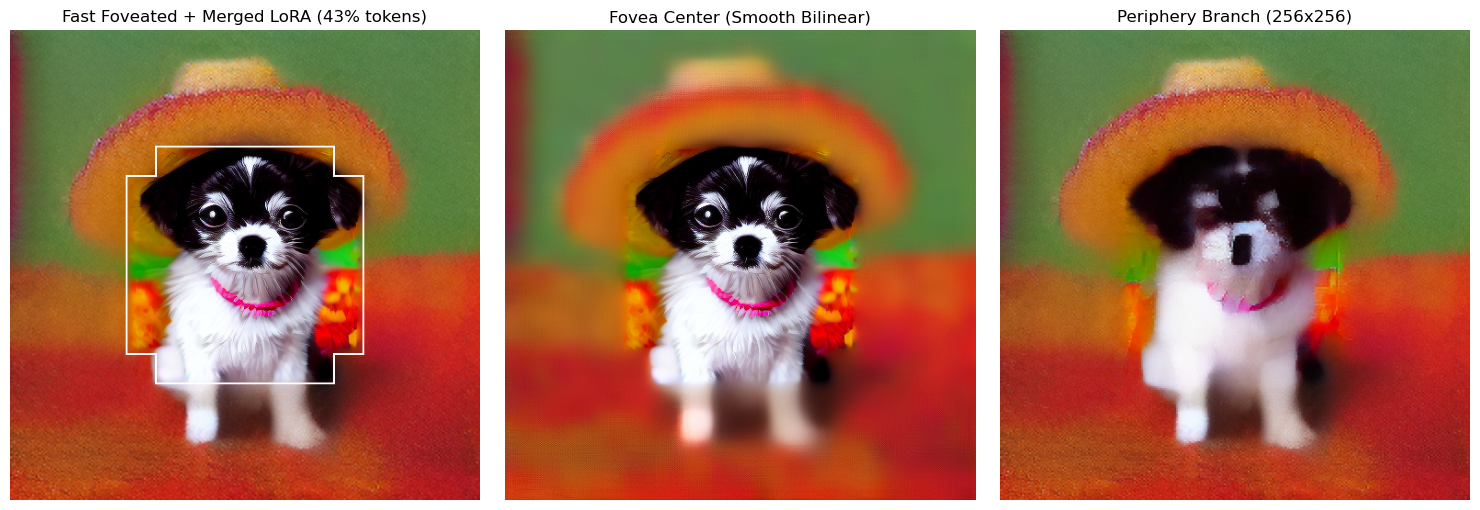

In [52]:
import os
import gc
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
from diffusers import AutoencoderKL, Transformer2DModel, DPMSolverMultistepScheduler
from transformers import T5EncoderModel, T5Tokenizer
from peft import PeftModel

# 1. ניקוי שרידי אימון ו-VRAM
for var in ["optimizer", "cached_x0", "cached_text_embeds", "cached_text_masks"]:
    if var in globals():
        del globals()[var]
gc.collect()
torch.cuda.empty_cache()

# 2. פונקציות עזר מרחביות (הגדרה עצמאית למניעת תלות)
def to_pil(t):
    img = (t.detach().cpu().float().clamp(-1, 1) + 1) / 2
    return Image.fromarray((img.squeeze(0).permute(1, 2, 0).numpy() * 255).astype(np.uint8))

def patchify(x):
    B, c, h, w = x.shape
    return x.reshape(B, c, h // P, P, w // P, P).permute(0, 2, 4, 3, 5, 1).reshape(B, -1, P * P * c)

def unpatchify(x, gh, gw):
    B, _, _ = x.shape
    return x.reshape(B, gh, gw, P, P, C).permute(0, 5, 1, 3, 2, 4).reshape(B, C, gh * P, gw * P)

def draw_fovea_border(pil_img, layout, color="red", width=3):
    img_draw = pil_img.copy()
    draw = ImageDraw.Draw(img_draw)
    M = layout["M"].cpu().numpy()
    gh, gw = M.shape
    w_px, h_px = pil_img.size
    
    # חילוץ מרכז ורדיוס מהמסיכה
    y_indices, x_indices = np.where(M)
    if len(x_indices) > 0 and len(y_indices) > 0:
        cx = (x_indices.min() + x_indices.max()) / 2.0 / gw * w_px
        cy = (y_indices.min() + y_indices.max()) / 2.0 / gh * h_px
        r = ((x_indices.max() - x_indices.min()) / 2.0 / gw) * w_px
        draw.ellipse([cx - r, cy - r, cx + r, cy + r], outline=color, width=width)
    return img_draw

# 3. טעינת הטרנספורמר ומיזוג ה-LoRA (עצמאי לחלוטין)
print("Ensuring Transformer & LoRA are loaded...")
if "transformer" not in globals() or transformer is None or hasattr(transformer, "peft_config"):
    transformer = Transformer2DModel.from_pretrained(
        model_id, subfolder="transformer", torch_dtype=torch.bfloat16
    ).to(device)
    
    if os.path.exists(lora_dir):
        print(f" Loading LoRA weights from '{lora_dir}'...")
        transformer = PeftModel.from_pretrained(transformer, lora_dir)
        transformer = transformer.merge_and_unload()
    else:
        print(" Warning: No LoRA weights found. Running zero-shot base model.")

transformer.eval()
base_model = transformer
P = base_model.config.patch_size       # 2
C = base_model.config.in_channels      # 4
D = base_model.inner_dim               # 1152
pe_layer = base_model.pos_embed
GRID = pe_layer.height                 # 32
model_dtype = pe_layer.proj.weight.dtype

# 4. טעינת VAE ו-Scheduler
if "vae" not in globals() or vae is None:
    vae = AutoencoderKL.from_pretrained(
        model_id, subfolder="vae", torch_dtype=torch.float16
    ).to(device)

if "scheduler" not in globals() or scheduler is None:
    scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

# 5. קידוד פרומפט אינפרנס ספציפי (בדיקה עצמאית)
test_prompt = "A cute pug dog sitting wearing a colourful sombrero, high resolution, highly detailed"

print(f"Encoding inference prompt: '{test_prompt}'...")
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(
    model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16
).to(device)

with torch.no_grad():
    txt_in = tokenizer(
        [test_prompt, ""], padding="max_length", max_length=120, truncation=True, return_tensors="pt"
    ).to(device)
    prompt_embeds = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0].to(model_dtype)
    prompt_attention_mask = txt_in.attention_mask.to(device)

del text_encoder, tokenizer
torch.cuda.empty_cache()

# 6. הגדרת פובאה במרכז התמונה
M = make_circular_mask(center=(0.5, 0.5), radius=0.28, grid=GRID)
layout = build_layout(M)

# 7. מעבר קדמי מהיר
@torch.no_grad()
def fov_transformer_inference(x, t, layout, p_emb, p_mask):
    B = x.shape[0]
    base = transformer
    pe = base.pos_embed

    W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C).to(model_dtype)
    bias = pe.proj.bias.to(model_dtype) if pe.proj.bias is not None else None
    h = F.linear(x, W_in, bias) + layout["pos"].to(model_dtype)

    t_emb, t_raw = base.adaln_single(
        t.expand(B), {"resolution": None, "aspect_ratio": None},
        batch_size=B, hidden_dtype=model_dtype
    )
    enc = base.caption_projection(p_emb).view(B, -1, D)
    enc_bias = ((1 - p_mask.to(model_dtype)) * -10000.0).unsqueeze(1)

    for block in base.transformer_blocks:
        h = block(
            h,
            attention_mask=None,
            encoder_hidden_states=enc,
            encoder_attention_mask=enc_bias,
            timestep=t_emb,
            cross_attention_kwargs=None,
            class_labels=None
        )

    shift, scale = (base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    h = base.norm_out(h) * (1 + scale) + shift
    out = base.proj_out(h)
    out = out.reshape(B, -1, P * P, base.out_channels)[..., :C]
    return out.reshape(B, -1, P * P * C)

# 8. יצירת רעש התחלתי פוביאלי
def foveated_noise(layout, seed=42):
    g = torch.Generator(device=device).manual_seed(seed)
    lat_hi = torch.randn(1, C, layout["h"] * P, layout["w"] * P, generator=g, device=device, dtype=model_dtype)
    lat_lo = (F.avg_pool2d(lat_hi.float(), 2) * 2).to(model_dtype)
    return torch.cat([patchify(lat_hi)[:, layout["hi_idx"]], patchify(lat_lo)[:, layout["lo_idx"]]], dim=1)

# 9. לולאת דיפוזיה מהירה (20 צעדים)
@torch.no_grad()
def generate_foveated_fast(seed=42, steps=20, guidance_scale=3.5):
    scheduler.set_timesteps(steps)
    x = foveated_noise(layout, seed) * scheduler.init_noise_sigma

    print(f"Generating image ({layout['token_ratio']*100:.0f}% tokens)...")
    for t in tqdm(scheduler.timesteps):
        t = t.to(device)
        x_in = scheduler.scale_model_input(torch.cat([x] * 2), t).to(model_dtype)

        eps_pred = fov_transformer_inference(x_in, t, layout, prompt_embeds, prompt_attention_mask)
        eps_uncond, eps_text = eps_pred.chunk(2)
        eps = eps_uncond + guidance_scale * (eps_text - eps_uncond)

        x = scheduler.step(eps, t, x).prev_sample
    return x

# 10. פונקציית פיענוח מכויל (Bilinear + Latent Calibration + ריכוך גבול)
@torch.no_grad()
def decode_foveated_smooth(x, layout):
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    hi = torch.zeros(1, h * w, P * P * C, device=device, dtype=x.dtype)
    lo = torch.zeros(1, (h // 2) * (w // 2), P * P * C, device=device, dtype=x.dtype)
    hi[:, layout["hi_idx"]] = x[:, :n_hi]
    lo[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi, z_lo = unpatchify(hi, h, w), unpatchify(lo, h // 2, w // 2)

    # כיול משרעת
    std_ratio = z_hi.std() / (z_lo.std() + 1e-6)
    z_lo = (z_lo - z_lo.mean()) * std_ratio + z_hi.mean()
    z_lo = z_lo.clamp(-3.0, 3.0)
    z_hi = z_hi.clamp(-3.0, 3.0)

    m_hi = layout["M"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    m_lo = layout["Mb"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    z_lo = torch.where(m_lo, F.avg_pool2d(z_hi.float(), 2).to(z_hi.dtype), z_lo)

    # שחזור bilinear חלק
    z_hi_smooth = F.interpolate(z_lo.float(), scale_factor=2, mode="bilinear", align_corners=False).to(z_hi.dtype)
    z_hi = torch.where(m_hi, z_hi, z_hi_smooth)

    img_hi = vae.decode((z_hi / vae.config.scaling_factor).to(vae.dtype)).sample
    img_lo = vae.decode((z_lo / vae.config.scaling_factor).to(vae.dtype)).sample
    img_lo_up = F.interpolate(img_lo.float(), scale_factor=2, mode="bicubic")

    # ריכוך גבולות ממוקד
    m_px = layout["M"].float().repeat_interleave(P * 8, 0).repeat_interleave(P * 8, 1).unsqueeze(0).to(device)
    m_px_smooth = TF.gaussian_blur(m_px, kernel_size=[11, 11], sigma=[3.0, 3.0]).squeeze(0)

    img = m_px_smooth * img_hi.float() + (1.0 - m_px_smooth) * img_lo_up
    return to_pil(img), to_pil(img_hi), to_pil(img_lo)

In [ ]:
latents_out = generate_foveated_fast(seed=42, steps=20, guidance_scale=3.5)
img_blend, img_hi, img_lo = decode_foveated_smooth(latents_out, layout)
img_with_border = draw_fovea_border(img_blend, layout)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img_with_border)
axs[0].set_title(f"Fast Foveated + Merged LoRA ({layout['token_ratio']*100:.0f}% tokens)")
axs[0].axis("off")

axs[1].imshow(img_hi)
axs[1].set_title("Fovea Center (Smooth Bilinear)")
axs[1].axis("off")

axs[2].imshow(img_lo)
axs[2].set_title("Periphery Branch (256x256)")
axs[2].axis("off")

plt.tight_layout()
plt.show()

# 🔵6) upgrading to 1024x1024 images

In [55]:
import torch
import torchvision.transforms as T
import gc
from tqdm.auto import tqdm
from datasets import load_dataset
from diffusers import AutoencoderKL
from transformers import T5EncoderModel, T5Tokenizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# שימוש במודל ה-512 שכבר שמור אצלך מקומית בדיסק כדי למנוע הורדה חוזרת של 10GB
cached_model_id = "PixArt-alpha/PixArt-XL-2-512x512"

# 1. טעינת 1,000 דוגמאות מ-DiffusionDB
print("1. Loading 1,000 samples from DiffusionDB...")
dataset = load_dataset("poloclub/diffusiondb", "2m_random_1k", split="train")

# 2. קידוד טקסט ב-T5 מתוך הקאש המקומי (שליפה מיידית ללא שום הורדה)
print("2. Caching 1,000 Text Embeddings (from local cache)...")
tokenizer = T5Tokenizer.from_pretrained(cached_model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(
    cached_model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16
).to(device)

cached_text_embeds = []
cached_text_masks = []

with torch.no_grad():
    for item in tqdm(dataset, desc="Encoding prompts"):
        prompt = item["prompt"]
        txt_in = tokenizer(
            prompt, padding="max_length", max_length=120, truncation=True, return_tensors="pt"
        ).to(device)
        emb = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0]
        cached_text_embeds.append(emb.cpu())
        cached_text_masks.append(txt_in.attention_mask.cpu())

del text_encoder, tokenizer
torch.cuda.empty_cache()
gc.collect()

# 3. קידוד תמונות 1024x1024 דרך ה-VAE המקומי (שליפה מיידית ללא הורדה)
print("3. Encoding 1,000 images at 1024x1024 via local VAE...")
vae = AutoencoderKL.from_pretrained(
    cached_model_id, subfolder="vae", torch_dtype=torch.bfloat16
).to(device)
vae.enable_tiling()  # מונע חריגת זיכרון ב-1024 על 8GB VRAM

img_transform = T.Compose([
    T.Resize((1024, 1024)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

cached_x0 = []

with torch.no_grad():
    for item in tqdm(dataset, desc="VAE 1024 Encoding"):
        img = item["image"].convert("RGB")
        img_tensor = img_transform(img).unsqueeze(0).to(device=device, dtype=torch.bfloat16)
        
        # לטנט נקי בגודל (1, 4, 128, 128)
        latent = vae.encode(img_tensor).latent_dist.sample()
        latent = latent * vae.config.scaling_factor
        cached_x0.append(latent.cpu())

del vae
torch.cuda.empty_cache()
gc.collect()

print(f"Caching complete! {len(cached_x0)} latents (128x128) ready in RAM.")
print(f"VRAM allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

1. Loading 1,000 samples from DiffusionDB...
2. Caching 1,000 Text Embeddings (from local cache)...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Encoding prompts:   0%|          | 0/1000 [00:00<?, ?it/s]

3. Encoding 1,000 images at 1024x1024 via local VAE...


VAE 1024 Encoding:   0%|          | 0/1000 [00:00<?, ?it/s]

Caching complete! 1000 latents (128x128) ready in RAM.
VRAM allocated: 1.19 GB


In [59]:
import torch.nn.functional as F
from PIL import Image
import numpy as np
from diffusers import Transformer2DModel
from peft import LoraConfig, get_peft_model

print("Loading 1024 Transformer & Initializing LoRA...")
transformer = Transformer2DModel.from_pretrained(
    model_id, subfolder="transformer", torch_dtype=torch.bfloat16
).to(device)

# הזרקת LoRA לשכבות ה-Attention וה-MLP
lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    target_modules=[
        "to_q", "to_k", "to_v", "to_out.0",
        "net.0.proj", "net.2"
    ],
    lora_dropout=0.05,
    bias="none"
)

transformer = get_peft_model(transformer, lora_config)
transformer.enable_gradient_checkpointing()
transformer.print_trainable_parameters()

base_model = transformer.base_model.model
P = base_model.config.patch_size       # 2
C = base_model.config.in_channels      # 4
D = base_model.inner_dim               # 1152
pe_layer = base_model.pos_embed
GRID = pe_layer.height                 # 64 עבור מודל ה-1024!
POS_SCALE = pe_layer.base_size / pe_layer.height / pe_layer.interpolation_scale

# --- פונקציות עזר מרחביות מותאמות לגריד 64x64 ---
def patchify(x):
    # x: (B, C, H, W) -> (B, H/P * W/P, P*P*C)
    B, c, h, w = x.shape
    return x.reshape(B, c, h // P, P, w // P, P).permute(0, 2, 4, 3, 5, 1).reshape(B, -1, P * P * c)

def unpatchify(x, gh, gw):
    # x: (B, gh*gw, P*P*C) -> (B, C, gh*P, gw*P)
    B, _, _ = x.shape
    return x.reshape(B, gh, gw, P, P, C).permute(0, 5, 1, 3, 2, 4).reshape(B, C, gh * P, gw * P)

def make_circular_mask(center=(0.5, 0.5), radius=0.30, grid=GRID):
    cy, cx = center
    y = torch.linspace(0, 1, grid).unsqueeze(1)
    x = torch.linspace(0, 1, grid).unsqueeze(0)
    dist = torch.sqrt((y - cy)**2 + (x - cx)**2)
    return dist <= radius

def build_layout(M):
    gh, gw = M.shape
    M_lo = M.view(gh // 2, 2, gw // 2, 2).any(dim=3).any(dim=1)
    
    hi_idx = torch.nonzero(M.flatten(), as_tuple=True)[0]
    lo_idx = torch.nonzero((~M_lo).flatten(), as_tuple=True)[0]

    # חילוץ סוג הנתונים ישירות מהשכבה (bfloat16)
    model_dtype = pe_layer.proj.weight.dtype

    # חילוץ Pos Embeddings עם dtype תואם
    pos_hi = pe_layer(
        torch.zeros(1, C, gh * P, gw * P, device=device, dtype=model_dtype)
    ).squeeze(0)[hi_idx]
    
    pos_lo = pe_layer(
        torch.zeros(1, C, (gh // 2) * P, (gw // 2) * P, device=device, dtype=model_dtype)
    ).squeeze(0)[lo_idx]
    
    pos_combined = torch.cat([pos_hi, pos_lo], dim=0).unsqueeze(0)

    return {
        "h": gh, "w": gw,
        "M": M, "Mb": M_lo,
        "hi_idx": hi_idx, "lo_idx": lo_idx,
        "n_hi": len(hi_idx), "n_lo": len(lo_idx),
        "pos": pos_combined,
        "token_ratio": (len(hi_idx) + len(lo_idx)) / (gh * gw)
    }

def to_pil(t):
    img = (t.detach().cpu().float().clamp(-1, 1) + 1) / 2
    return Image.fromarray((img.squeeze(0).permute(1, 2, 0).numpy() * 255).astype(np.uint8))

Loading 1024 Transformer & Initializing LoRA...


Some weights of the model checkpoint at PixArt-alpha/PixArt-XL-2-1024-MS were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


trainable params: 26,836,992 || all params: 638,186,144 || trainable%: 4.2052


In [ ]:
import time
import random
from diffusers import DPMSolverMultistepScheduler

scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

# פונקציית מעבר קדמי לטוקנים היברידיים
def fov_transformer_train(model, x, t, layout, prompt_embeds, prompt_attention_mask):
    B = x.shape[0]
    base = model.base_model.model if hasattr(model, "base_model") else model
    pe = base.pos_embed
    
    W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C).to(x.dtype)
    bias = pe.proj.bias.to(x.dtype) if pe.proj.bias is not None else None
    h = F.linear(x, W_in, bias) + layout["pos"].to(x.dtype)

    # התניית רזולוציה מקורית של 1024
    res = torch.tensor([1024, 1024], dtype=h.dtype, device=device).repeat(B, 1)
    ar = torch.tensor([1.0], dtype=h.dtype, device=device).repeat(B, 1)
    cond = {"resolution": res, "aspect_ratio": ar}

    t_emb, t_raw = base.adaln_single(t.expand(B), cond, batch_size=B, hidden_dtype=h.dtype)
    enc = base.caption_projection(prompt_embeds).view(B, -1, D)
    enc_bias = ((1 - prompt_attention_mask.to(h.dtype)) * -10000.0).unsqueeze(1)

    for block in base.transformer_blocks:
        h = block(
            h,
            attention_mask=None,
            encoder_hidden_states=enc,
            encoder_attention_mask=enc_bias,
            timestep=t_emb,
            cross_attention_kwargs=None,
            class_labels=None
        )

    shift, scale = (base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    h = base.norm_out(h) * (1 + scale) + shift
    out = base.proj_out(h)
    out = out.reshape(B, -1, P * P, base.out_channels)[..., :C]
    return out.reshape(B, -1, P * P * C)

optimizer = torch.optim.AdamW(transformer.parameters(), lr=1e-4, weight_decay=1e-2)

def train_foveated_lora_1024(num_steps=6000, max_minutes=52):
    transformer.train()
    progress_bar = tqdm(range(num_steps), desc="Training LoRA 1024 (~150 mins)")
    start_time = time.time()
    
    for step in progress_bar:
        elapsed_min = (time.time() - start_time) / 60.0
        if elapsed_min > max_minutes:
            print(f"\nReached time limit of {max_minutes} mins. Finishing gracefully.")
            break

        idx = random.randint(0, len(cached_x0) - 1)
        x0 = cached_x0[idx].to(device=device, dtype=torch.bfloat16)
        p_emb = cached_text_embeds[idx].to(device=device, dtype=torch.bfloat16)
        p_mask = cached_text_masks[idx].to(device=device)

        # אוגמנטציה מרחבית בגריד 64
        c_y, c_x = random.uniform(0.3, 0.7), random.uniform(0.3, 0.7)
        r = random.uniform(0.20, 0.38)
        M = make_circular_mask(center=(c_y, c_x), radius=r, grid=GRID)
        layout = build_layout(M)

        t = torch.randint(0, 1000, (1,), device=device).long()
        noise = torch.randn_like(x0)
        
        alpha_prod_t = scheduler.alphas_cumprod[t.item()]
        beta_prod_t = 1 - alpha_prod_t
        x_t = (alpha_prod_t ** 0.5) * x0 + (beta_prod_t ** 0.5) * noise

        # כיווץ הפריפריה פי 2
        x_t_lo = (F.avg_pool2d(x_t.float(), 2) * 2).to(torch.bfloat16)
        noise_lo = (F.avg_pool2d(noise.float(), 2) * 2).to(torch.bfloat16)

        x_t_fov = torch.cat([
            patchify(x_t)[:, layout["hi_idx"]],
            patchify(x_t_lo)[:, layout["lo_idx"]]
        ], dim=1)

        target_noise_fov = torch.cat([
            patchify(noise)[:, layout["hi_idx"]],
            patchify(noise_lo)[:, layout["lo_idx"]]
        ], dim=1)

        optimizer.zero_grad()
        pred_noise_fov = fov_transformer_train(transformer, x_t_fov, t, layout, p_emb, p_mask)
        loss = F.mse_loss(pred_noise_fov, target_noise_fov)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(transformer.parameters(), max_norm=1.0)
        optimizer.step()

        progress_bar.set_postfix({"Loss": f"{loss.item():.4f}", "Time": f"{elapsed_min:.1f}m"})

        if (step + 1) % 1500 == 0:
            transformer.save_pretrained(f"./checkpoint_1024_step_{step+1}")

    transformer.save_pretrained("./pixart_1024_foveated_lora_final")
    print("\nTraining completed! Saved to ./pixart_1024_foveated_lora_final")

# הרצת האימון
train_foveated_lora_1024(num_steps=15000, max_minutes=1000)

Training LoRA 1024 (~50 mins):   0%|          | 0/15000 [00:00<?, ?it/s]

In [ ]:
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import gc
from tqdm.auto import tqdm
from diffusers import AutoencoderKL, Transformer2DModel, DPMSolverMultistepScheduler
from transformers import T5EncoderModel, T5Tokenizer
from peft import PeftModel

# 1. ניקוי זיכרון
for var in ["optimizer", "cached_x0", "cached_text_embeds", "cached_text_masks"]:
    if var in globals():
        del globals()[var]
gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_id = "PixArt-alpha/PixArt-XL-2-1024-MS"

# 2. טעינת המודל ומיזוג ה-LoRA (עצמאי לחלוטין)
print("Loading Transformer & Merging 1024 LoRA...")
transformer = Transformer2DModel.from_pretrained(
    model_id, subfolder="transformer", torch_dtype=torch.bfloat16
).to(device)

# אם המשקולות בדיסק, נטען ונמזג:
lora_path = "./pixart_1024_foveated_lora_final"
transformer = PeftModel.from_pretrained(transformer, lora_path)
transformer = transformer.merge_and_unload()
transformer.eval()

model_dtype = torch.bfloat16

# 3. טעינת VAE ו-Scheduler
vae = AutoencoderKL.from_pretrained(
    model_id, subfolder="vae", torch_dtype=torch.float16
).to(device)
vae.enable_tiling()  # קריטי למניעת OOM ב-1024 על 8GB VRAM

scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

# 4. קידוד פרומפט אינפרנס
test_prompt = "A cute pug dog sitting wearing a colourful sombrero, shallow depth of field, high detail"
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16).to(device)

with torch.no_grad():
    txt_in = tokenizer([test_prompt, ""], padding="max_length", max_length=120, truncation=True, return_tensors="pt").to(device)
    prompt_embeds = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0]
    prompt_attention_mask = txt_in.attention_mask

del text_encoder, tokenizer
torch.cuda.empty_cache()

# 5. הגדרת פובאה מרווחת (כיסוי מלא של האובייקט - רדיוס 0.32)
M = make_circular_mask(center=(0.5, 0.5), radius=0.32, grid=GRID)
layout = build_layout(M)

# 6. מעבר קדמי מותאם ל-1024
@torch.no_grad()
def fov_transformer_inference_1024(x, t, layout, p_emb, p_mask):
    B = x.shape[0]
    base = transformer
    pe = base.pos_embed

    W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C).to(model_dtype)
    bias = pe.proj.bias.to(model_dtype) if pe.proj.bias is not None else None
    h = F.linear(x, W_in, bias) + layout["pos"].to(model_dtype)

    res = torch.tensor([1024, 1024], dtype=model_dtype, device=device).repeat(B, 1)
    ar = torch.tensor([1.0], dtype=model_dtype, device=device).repeat(B, 1)
    cond = {"resolution": res, "aspect_ratio": ar}

    t_emb, t_raw = base.adaln_single(t.expand(B), cond, batch_size=B, hidden_dtype=model_dtype)
    enc = base.caption_projection(p_emb).view(B, -1, D)
    enc_bias = ((1 - p_mask.to(model_dtype)) * -10000.0).unsqueeze(1)

    for block in base.transformer_blocks:
        h = block(
            h,
            attention_mask=None,
            encoder_hidden_states=enc,
            encoder_attention_mask=enc_bias,
            timestep=t_emb,
            cross_attention_kwargs=None,
            class_labels=None
        )

    shift, scale = (base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    h = base.norm_out(h) * (1 + scale) + shift
    out = base.proj_out(h)
    out = out.reshape(B, -1, P * P, base.out_channels)[..., :C]
    return out.reshape(B, -1, P * P * C)

# 7. יצירת רעש התחלתי פוביאלי
def foveated_noise(layout, seed=42):
    g = torch.Generator(device=device).manual_seed(seed)
    lat_hi = torch.randn(1, C, layout["h"] * P, layout["w"] * P, generator=g, device=device, dtype=model_dtype)
    lat_lo = (F.avg_pool2d(lat_hi.float(), 2) * 2).to(model_dtype)
    return torch.cat([patchify(lat_hi)[:, layout["hi_idx"]], patchify(lat_lo)[:, layout["lo_idx"]]], dim=1)

# 8. לולאת אינפרנס מהירה (20 צעדים)
@torch.no_grad()
def generate_foveated_1024(seed=42, steps=20, guidance_scale=3.5):
    scheduler.set_timesteps(steps)
    x = foveated_noise(layout, seed) * scheduler.init_noise_sigma

    print(f"Generating 1024x1024 with {layout['token_ratio']*100:.0f}% tokens...")
    for t in tqdm(scheduler.timesteps):
        t = t.to(device)
        x_in = scheduler.scale_model_input(torch.cat([x] * 2), t).to(model_dtype)

        eps_pred = fov_transformer_inference_1024(x_in, t, layout, prompt_embeds, prompt_attention_mask)
        eps_uncond, eps_text = eps_pred.chunk(2)
        eps = eps_uncond + guidance_scale * (eps_text - eps_uncond)

        x = scheduler.step(eps, t, x).prev_sample
    return x

# 9. פיענוח מכויל (Bilinear + Latent Calibration + Bokeh טבעי)
@torch.no_grad()
def decode_foveated_1024_smooth(x, layout):
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    hi = torch.zeros(1, h * w, P * P * C, device=device, dtype=x.dtype)
    lo = torch.zeros(1, (h // 2) * (w // 2), P * P * C, device=device, dtype=x.dtype)
    hi[:, layout["hi_idx"]] = x[:, :n_hi]
    lo[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi, z_lo = unpatchify(hi, h, w), unpatchify(lo, h // 2, w // 2)

    # כיול משרעת הפריפריה
    std_ratio = z_hi.std() / (z_lo.std() + 1e-6)
    z_lo = (z_lo - z_lo.mean()) * std_ratio + z_hi.mean()
    z_lo = z_lo.clamp(-3.0, 3.0)
    z_hi = z_hi.clamp(-3.0, 3.0)

    m_hi = layout["M"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    m_lo = layout["Mb"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    z_lo = torch.where(m_lo, F.avg_pool2d(z_hi.float(), 2).to(z_hi.dtype), z_lo)

    # שחזור פריפריה חלק ב-bilinear
    z_hi_smooth = F.interpolate(z_lo.float(), scale_factor=2, mode="bilinear", align_corners=False).to(z_hi.dtype)
    z_hi = torch.where(m_hi, z_hi, z_hi_smooth)

    img_hi = vae.decode((z_hi / vae.config.scaling_factor).to(vae.dtype)).sample
    img_lo = vae.decode((z_lo / vae.config.scaling_factor).to(vae.dtype)).sample
    img_lo_up = F.interpolate(img_lo.float(), scale_factor=2, mode="bicubic")

    # ריכוך גאוסי ממוקד לגבול (סיגמא מתונה לשמירה על חדות)
    m_px = layout["M"].float().repeat_interleave(P * 8, 0).repeat_interleave(P * 8, 1).unsqueeze(0).to(device)
    m_px_smooth = TF.gaussian_blur(m_px, kernel_size=[11, 11], sigma=[3.0, 3.0]).squeeze(0)

    img = m_px_smooth * img_hi.float() + (1.0 - m_px_smooth) * img_lo_up
    return to_pil(img), to_pil(img_hi), to_pil(img_lo)

# 10. הרצה והצגה
latents_out = generate_foveated_1024(seed=42, steps=20, guidance_scale=3.5)
img_blend, img_hi, img_lo = decode_foveated_1024_smooth(latents_out, layout)

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(img_blend)
axs[0].set_title(f"1024x1024 Foveated Result ({layout['token_ratio']*100:.0f}% tokens)")
axs[0].axis("off")

axs[1].imshow(img_hi)
axs[1].set_title("Full Res Center (1024x1024)")
axs[1].axis("off")

axs[2].imshow(img_lo)
axs[2].set_title("Periphery Bokeh (512x512)")
axs[2].axis("off")

plt.tight_layout()
plt.show()